# External Image Comparison — YOLO vs U-Net

Este experimento aplica os **checkpoints já treinados** ao mesmo conjunto de imagens de colonoscopia,
externas. Para conferir o fluxo após os treinamentos, também permite selecionar o teste interno.
O relatório identifica o conjunto utilizado; resultados internos não medem generalização externa.
Não há treinamento neste notebook.

O próprio notebook apresenta o relatório: resumo das métricas, resultados por imagem, configurações
e comparação visual. Os arquivos CSV e JSON são exportações desses mesmos resultados.

Antes de executar, informe os checkpoints treinados. Os caminhos padrão correspondem
aos experimentos descritos no README. Escolha `CONJUNTO = "interno"` para o teste preparado pelo projeto ou
`"externo"` para suas imagens e anotações. O padrão é externo.
Na ausência de imagens ou checkpoints, a avaliação informa os arquivos necessários.

**Protocolo:** escolha os limiares na validação e fixe-os antes do teste externo. Registre a origem das imagens,
verifique duplicatas com os dados do treinamento e use o mesmo conjunto para os dois modelos.
Imagens parecidas ou do mesmo exame não são observações independentes.

In [1]:
from pathlib import Path
import csv
import html
import json
import sys
from datetime import datetime

import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import HTML, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / "src/unet.py").is_file():
    raise RuntimeError("Abra o notebook a partir da raiz do projeto ou da pasta notebooks")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from avaliacao_externa import (
    EXTENSOES, carregar_casos, carregar_casos_internos, carregar_referencia, executar_avaliacao, ler_imagem, sha256,
)
from prediz_yolo import carregar_yolo
from prediz_unet import carregar_unet
from config import DADOS, PESOS_YOLO as DEFAULT_YOLO, PESOS_UNET as DEFAULT_UNET

## 1. Configuração

Os caminhos padrão correspondem a `--nome yolo-polyp` e `--nome unet-polyp`.
Para usar o experimento `s640_grupo`, troque `PESOS_YOLO` por
`ROOT / "runs/s640_grupo/weights/best.pt"`. Treinos novos com outro nome também exigem atualizar esse caminho.
`DEVICE = "cpu"` funciona sem CUDA; use `"cuda:0"` se houver GPU compatível.

Cada modelo mantém seu pré-processamento: YOLO recebe BGR em 640; U-Net recebe RGB na resolução registrada no checkpoint (padrão 384),
com a mesma normalização do treino. As máscaras são avaliadas na grade comum 384 × 384,
com o mesmo filtro de componentes menores que 500 pixels. O filtro pode afetar lesões pequenas;
registre essa escolha e use `AREA_MINIMA = 0` para um experimento separado sem filtro.
As sobreposições salvas voltam à resolução original, após esse processamento.

In [2]:
CONJUNTO = "externo"  # "interno" usa o split abaixo; "externo" usa ORIGEM e ANOTACOES
SPLIT_INTERNO = "test"  # "val" para calibração; nunca "train" para relatório de teste
ORIGEM = ROOT / "data/external/images"
ANOTACOES = None  # Ou ROOT / "data/external/anotacoes.csv"
PESOS_YOLO = DEFAULT_YOLO
PESOS_UNET = DEFAULT_UNET
DEVICE = "cpu"
YOLO_IMGSZ, YOLO_CONF = 640, 0.25
UNET_LIMIAR = 0.5
GRADE, AREA_MINIMA = 384, 500
EXECUTAR_YOLO, EXECUTAR_UNET = True, True
N_PAINEIS = 6
PREFIXO = "comparacao_externa" if CONJUNTO == "externo" else f"comparacao_interna_{SPLIT_INTERNO}"
SAIDA = ROOT / "runs" / f"{PREFIXO}_{datetime.now():%Y%m%d_%H%M%S_%f}"

for nome, caminho in [("Imagens externas", ORIGEM), ("Pesos YOLO", PESOS_YOLO),
                       ("Pesos U-Net", PESOS_UNET)]:
    exibicao = caminho.relative_to(ROOT) if caminho.is_relative_to(ROOT) else caminho
    print(f"{nome}: {'disponível' if caminho.exists() else 'PENDENTE'} — {exibicao}")
print("Conjunto:", CONJUNTO, SPLIT_INTERNO if CONJUNTO == "interno" else "")
print("Anotações externas:", ANOTACOES if ANOTACOES else "não informadas; apenas análise visual")
print("Dispositivo:", DEVICE)

Imagens externas: PENDENTE — data/external/images
Pesos YOLO: PENDENTE — runs/yolo-polyp/weights/best.pt
Pesos U-Net: PENDENTE — runs/unet-polyp/weights/best.pt
Conjunto: externo 
Anotações externas: não informadas; apenas análise visual
Dispositivo: cpu


## 2. Imagens e anotações

No modo interno, as referências vêm de `data/processed/Kvasir-SEG`, com os mesmos splits
usados pelos dois treinamentos. Um label vazio confirma negativo; máscara positiva ausente é erro.

No modo externo, o CSV opcional possui `imagem,mascara,presenca,origem`; veja `examples/anotacoes.exemplo.csv`.
`imagem` é relativa a `ORIGEM`; `mascara` é relativa à pasta do CSV. A máscara deve ser binária
(fundo 0, pólipo > 0), ter o mesmo tamanho da imagem e representar todos os pólipos.

- Máscara informada: permite Dice/IoU e determina a presença de pólipo.
- `presenca=0`, sem máscara: negativo confirmado, usado para falsos positivos.
- `presenca=1`, sem máscara: permite avaliação de presença por imagem, sem Dice/IoU.
- Presença e máscara vazias, ou imagem fora do CSV: **sem anotação**, apenas análise visual.

Uma máscara citada mas ausente, dimensões incompatíveis ou presença contraditória interrompem a avaliação.
Não se presume que a ausência de anotação seja um negativo.

In [3]:
if CONJUNTO == "interno":
    if SPLIT_INTERNO not in {"val", "test"}:
        raise ValueError("Use val ou test para a comparação interna")
    casos = carregar_casos_internos(DADOS, SPLIT_INTERNO) if (DADOS / "data.yaml").is_file() else []
elif CONJUNTO == "externo":
    disponiveis = ORIGEM.is_file() or (ORIGEM.is_dir() and any(
        p.is_file() and p.suffix.lower() in EXTENSOES for p in ORIGEM.rglob("*")
    ))
    casos = carregar_casos(ORIGEM, ANOTACOES) if disponiveis else []
else:
    raise ValueError("CONJUNTO deve ser interno ou externo")
CONFIG_CONJUNTO = {"conjunto": CONJUNTO, "split": SPLIT_INTERNO if CONJUNTO == "interno" else None}
if not casos:
    print("Pendente: prepare os dados internos ou adicione as imagens externas configuradas. Nenhum modelo será executado.")
else:
    # Valida todas as referências antes de iniciar qualquer modelo.
    for caso in casos:
        imagem = ler_imagem(caso["caminho"])
        carregar_referencia(caso, imagem.shape[:2])
    print(f"{len(casos)} imagens; ambos os modelos usarão essa mesma lista.")
    print("Com máscara:", sum(c["mascara"] is not None for c in casos))
    print("Origem não registrada:", sum(not c["origem"] for c in casos))
    for caso in casos[:5]:
        print(caso["imagem"], "| presença:", caso["presenca"], "| fonte:", caso["origem"] or "não informada")

Pendente: prepare os dados internos ou adicione as imagens externas configuradas. Nenhum modelo será executado.


## 3. Predição YOLO

Usa a mesma função de `src/prediz_yolo.py`: une as máscaras das instâncias,
aplica o filtro comum e salva máscara, sobreposição, CSV por imagem e JSON com configuração,
hashes dos pesos, imagens e anotações. `confianca_maxima` descreve a saída do YOLO,
não a probabilidade de acerto da avaliação. Os números de instâncias são anteriores ao filtro de área.

Referência da API: https://docs.ultralytics.com/modes/predict/

In [4]:
resultados = {}
if EXECUTAR_YOLO and casos and PESOS_YOLO.is_file():
    predizer_yolo, config_yolo = carregar_yolo(PESOS_YOLO, YOLO_IMGSZ, YOLO_CONF, DEVICE)
    resultados["yolo"] = executar_avaliacao(
        casos, predizer_yolo, SAIDA / "yolo", {**config_yolo, **CONFIG_CONJUNTO}, GRADE, AREA_MINIMA,
    )
    print("YOLO concluído:", resultados["yolo"]["resumo"])
else:
    print("YOLO não executado: desativado, sem imagens ou sem checkpoint local.")

YOLO não executado: desativado, sem imagens ou sem checkpoint local.


## 4. Predição U-Net

Usa `src/prediz_unet.py`, que lê arquitetura, resolução e normalização do checkpoint com configuração.
Também aceita o `state_dict` puro do baseline original (base 32, resolução 384).
Aplica sigmoide e limiar e projeta a máscara nativa diretamente à grade de avaliação comum.
A máscara só é redimensionada à imagem original ao salvar as exportações visuais.
A implementação funciona em CPU ou CUDA, sem iniciar treinamento.

In [5]:
if EXECUTAR_UNET and casos and PESOS_UNET.is_file():
    predizer_unet, config_unet = carregar_unet(PESOS_UNET, DEVICE, UNET_LIMIAR)
    resultados["unet"] = executar_avaliacao(
        casos, predizer_unet, SAIDA / "unet", {**config_unet, **CONFIG_CONJUNTO}, GRADE, AREA_MINIMA,
    )
    print("U-Net concluída:", resultados["unet"]["resumo"])
else:
    print("U-Net não executada: desativada, sem imagens ou sem checkpoint local.")

U-Net não executada: desativada, sem imagens ou sem checkpoint local.


## 5. Quantitative report

Para cada imagem positiva com máscara de referência $G$ e predição $P$:

$$Dice = \frac{2|P \cap G|}{|P|+|G|}, \qquad IoU = \frac{|P \cap G|}{|P \cup G|}.$$

As médias de Dice/IoU incluem somente imagens positivas com máscara; falhas sem predição entram com zero.
Máscaras positivas que desapareçam na grade reduzida não têm Dice/IoU calculados; confira o número
`n_mascaras_positivas` efetivamente avaliado. Negativos e casos desconhecidos não entram nessas médias.

A sensibilidade por imagem é $TP/(TP+FN)$ e a taxa de falsos positivos é $FP/(FP+TN)$.
Essas duas medidas verificam se houve **qualquer região prevista** na imagem, sem comprovar que a região
coincide com a lesão. Elas não representam recall por lesão; a localização é avaliada por Dice/IoU.
Sem positivos/negativos anotados, a respectiva métrica fica vazia, nunca é preenchida com zero.

É possível inspecionar só um modelo, mas a comparação completa exige os dois.

In [6]:
def mostrar_tabela(linhas):
    if not linhas:
        return
    campos = list(dict.fromkeys(k for linha in linhas for k in linha))
    def formatar(valor):
        if valor is None or valor == "":
            return "—"
        return f"{valor:.4f}" if isinstance(valor, float) else str(valor)
    cabecalho = "".join(f"<th>{html.escape(k)}</th>" for k in campos)
    corpo = "".join("<tr>" + "".join(
        f"<td>{html.escape(formatar(linha.get(k)))}</td>" for k in campos
    ) + "</tr>" for linha in linhas)
    display(HTML(f"<div style='overflow-x:auto'><table><thead><tr>{cabecalho}</tr></thead>"
                 f"<tbody>{corpo}</tbody></table></div>"))


comparacao = [{"modelo": nome, **r["resumo"]} for nome, r in resultados.items()]
if len(resultados) == 2:
    # Garante pareamento por imagem, conteúdo e anotação, não apenas mesma contagem.
    chaves = lambda r: [(e["imagem"], e["sha256"], e["mascara_sha256"], e["presenca"])
                       for e in r["entradas"]]
    assert chaves(resultados["yolo"]) == chaves(resultados["unet"]), "Conjuntos diferentes"
else:
    print("Comparação entre modelos pendente: são necessários resultados dos dois.")

if comparacao:
    display(HTML(f"<h3>Metrics summary — {CONJUNTO.upper()}</h3>"))
    mostrar_tabela(comparacao)

    display(HTML("<h3>Results by image</h3>"))
    por_imagem = []
    for nome, resultado in resultados.items():
        for linha in resultado["por_imagem"]:
            por_imagem.append({"modelo": nome, **{
                campo: linha[campo] for campo in (
                    "imagem", "origem", "presenca", "detectou", "resultado", "dice", "iou",
                )
            }})
    mostrar_tabela(por_imagem)

    display(HTML("<h3>Experiment configuration</h3>"))
    for nome, resultado in resultados.items():
        display(HTML(f"<h4>{nome.upper()}</h4>"))
        mostrar_tabela([{"parametro": "data_utc", "valor": resultado["data_utc"]}] + [
            {"parametro": k, "valor": str(v)} for k, v in resultado["config"].items()
        ])
    display(HTML("<h3>Image provenance</h3>"))
    mostrar_tabela([{
        "imagem": e["imagem"], "origem": e["origem"],
        "mascara_referencia": e["mascara"], "sha256": e["sha256"],
    } for e in next(iter(resultados.values()))["entradas"]])

    with (SAIDA / "comparacao.csv").open("w", encoding="utf-8", newline="") as f:
        escritor = csv.DictWriter(f, fieldnames=list(comparacao[0]))
        escritor.writeheader()
        escritor.writerows(comparacao)
    (SAIDA / "comparacao.json").write_text(json.dumps({
        "comparacao_completa": len(resultados) == 2,
        **CONFIG_CONJUNTO,
        "resumo": comparacao,
        "resultados": {nome: f"{nome}/resultado.json" for nome in resultados},
    }, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    print("Cópias dos resultados apresentadas neste notebook:", SAIDA)
else:
    print("Relatório pendente: adicione as imagens e os checkpoints para gerar os resultados aqui.")

Comparação entre modelos pendente: são necessários resultados dos dois.
Relatório pendente: adicione as imagens e os checkpoints para gerar os resultados aqui.


## 6. Inspeção lado a lado

Exibe até `N_PAINEIS` imagens na ordem da lista. Na coluna da referência, falta de anotação
é indicada explicitamente. As sobreposições são as máscaras já submetidas ao filtro comum.
Os painéis complementam as métricas e os resultados por imagem apresentados acima.

In [7]:
if resultados:
    indices = {nome: {l["imagem"]: l for l in r["por_imagem"]} for nome, r in resultados.items()}
    for caso in casos[:N_PAINEIS]:
        imagem = ler_imagem(caso["caminho"])
        rgb = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)
        gt, presenca = carregar_referencia(caso, imagem.shape[:2])
        fig, axes = plt.subplots(1, 2 + len(resultados), figsize=(5 * (2 + len(resultados)), 4))
        axes[0].imshow(rgb)
        axes[0].set_title("Original")
        if gt is not None:
            axes[1].imshow(gt, cmap="gray", vmin=0, vmax=1)
            axes[1].set_title("Referência" if gt.any() else "Negativo confirmado")
        else:
            axes[1].imshow(rgb)
            axes[1].set_title("Pólipo anotado, sem máscara" if presenca == 1 else "Sem anotação")
        for ax, nome in zip(axes[2:], resultados):
            linha = indices[nome][caso["imagem"]]
            overlay = ler_imagem(SAIDA / nome / linha["sobreposicao"])
            ax.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
            metricas = f"Dice {linha['dice']:.3f} | IoU {linha['iou']:.3f}" if linha["dice"] is not None else linha["resultado"]
            ax.set_title(f"{nome.upper()} — {metricas}")
        for ax in axes:
            ax.axis("off")
        fig.suptitle(caso["imagem"])
        plt.tight_layout()
        plt.show()
else:
    print("Painéis pendentes: execute a predição com imagens e checkpoints disponíveis.")

Painéis pendentes: execute a predição com imagens e checkpoints disponíveis.


## 7. Resultados registrados do baseline

A tabela e os gráficos abaixo apresentam os resultados do teste interno já registrados
em `artifacts/comparacao.json`. Esses valores pertencem ao experimento original e são
carregados do relatório versionado. Não são medições externas nem uma nova execução dos modelos.

O protocolo desta seção é o do experimento registrado. Para avaliar checkpoints com o
código atual, execute as seções anteriores com as imagens e os pesos correspondentes.


Fonte: artifacts/comparacao.json
Split: test | grade: 384x384 | área mínima: 500 pixels


modelo,dice,dice_mediana,dice_erro_padrao,iou,fp_fundos,falhas_dice_abaixo_0.5,acertos_dice_acima_0.9,n_positivos,n_fundos
YOLO,0.8861,0.9529,0.0197,0.8327,0.0693,6,78,100,101
UNET,0.8204,0.8982,0.0207,0.7357,0.0198,9,50,100,101


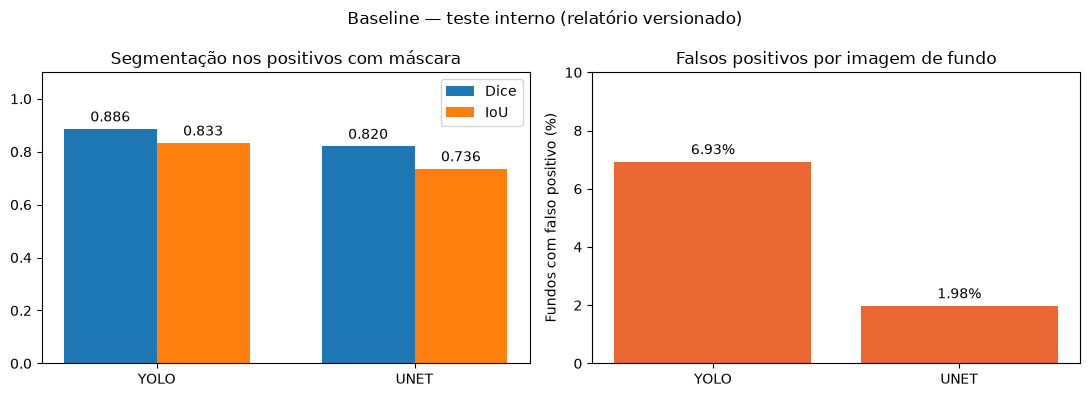

In [8]:
arquivo_baseline = ROOT / "artifacts/comparacao.json"
if not arquivo_baseline.is_file():
    print("Relatório do baseline não disponível em artifacts/comparacao.json.")
else:
    baseline = json.loads(arquivo_baseline.read_text(encoding="utf-8"))
    resumo_baseline = [{"modelo": nome.upper(), **{
        campo: baseline[nome][campo] for campo in (
            "dice", "dice_mediana", "dice_erro_padrao", "iou", "fp_fundos",
            "falhas_dice_abaixo_0.5", "acertos_dice_acima_0.9", "n_positivos", "n_fundos",
        )
    }} for nome in ("yolo", "unet")]
    print("Fonte: artifacts/comparacao.json")
    print(f"Split: {baseline['split']} | grade: {baseline['grade']} | área mínima: {baseline['area_minima']} pixels")
    mostrar_tabela(resumo_baseline)

    nomes = [r["modelo"] for r in resumo_baseline]
    x = np.arange(len(nomes))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for deslocamento, campo, rotulo in ((-0.18, "dice", "Dice"), (0.18, "iou", "IoU")):
        barras = axes[0].bar(x + deslocamento, [r[campo] for r in resumo_baseline], width=0.36, label=rotulo)
        axes[0].bar_label(barras, fmt="%.3f", padding=3)
    axes[0].set_xticks(x, nomes)
    axes[0].set_ylim(0, 1.1)
    axes[0].set_title("Segmentação nos positivos com máscara")
    axes[0].legend()
    barras = axes[1].bar(nomes, [100 * r["fp_fundos"] for r in resumo_baseline], color="#eb6834")
    axes[1].bar_label(barras, fmt="%.2f%%", padding=3)
    axes[1].set_ylabel("Fundos com falso positivo (%)")
    axes[1].set_title("Falsos positivos por imagem de fundo")
    axes[1].set_ylim(0, max(10, 120 * max(r["fp_fundos"] for r in resumo_baseline)))
    fig.suptitle("Baseline — teste interno (relatório versionado)")
    plt.tight_layout()
    plt.show()
    plt.close(fig)
